# 04 Evaluation and calibration

Metrics on validation and on the December test set, calibration analysis, operating point, permutation importance,
ablation plot. Also writes the LaTeX tables and the number macros used by the report and the slides, so no number in
the report is typed by hand.

The operating threshold is chosen on validation (precision >= 0.5 with the highest recall) and then applied unchanged
to December.

In [1]:
import json

import numpy as np
import pandas as pd
from sklearn.metrics import (average_precision_score, brier_score_loss, log_loss,
                             precision_recall_curve, roc_auc_score, roc_curve)
from xgboost import XGBClassifier

In [2]:
from pathlib import Path

ROOT = Path("..").resolve()
RAW_CSV = ROOT / "data_raw" / "flights.csv"
PROCESSED_DIR = ROOT / "data" / "processed"
MODEL_DIR = ROOT / "models"
RESULTS_DIR = ROOT / "results"
FIG_DIR = RESULTS_DIR / "figures"
TABLE_DIR = RESULTS_DIR / "tables"
for d in (PROCESSED_DIR, MODEL_DIR, FIG_DIR, TABLE_DIR):
    d.mkdir(parents=True, exist_ok=True)

SEED = 42
TARGET_PRECISION = 0.5

In [3]:
import matplotlib.pyplot as plt
%matplotlib inline

BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
GREY, LIGHT_GREY = "#8c8b86", "#c9c8c2"
TEXT, TEXT_2 = "#0b0b0b", "#52514e"
MODEL_COLORS = {"Prior rate": LIGHT_GREY, "Route history": GREY, "LR": BLUE, "XGBoost": ORANGE}

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    "font.size": 9, "axes.titlesize": 10, "axes.titleweight": "bold",
    "axes.labelcolor": TEXT_2, "axes.edgecolor": LIGHT_GREY,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.6,
    "xtick.color": TEXT_2, "ytick.color": TEXT_2,
    "lines.linewidth": 2, "legend.frameon": False, "text.color": TEXT,
})

In [4]:
with open(PROCESSED_DIR / "feature_columns.json") as f:
    cols = json.load(f)
CAT_COLS, NUM_COLS = cols["cat"], cols["num"]
ALL_FEATURES = CAT_COLS + NUM_COLS


def load_splits():
    df = pd.read_pickle(PROCESSED_DIR / "features.pkl")
    df = df[~df["no_arrival"]]
    return {s: df[df["split"] == s].reset_index(drop=True) for s in ("train", "val", "test")}

def to_xgb_frame(df, cols, categories):
    X = df[cols].copy()
    for c in CAT_COLS:
        if c in X:
            # levels never seen in training (a few new destinations) become missing
            known = X[c].where(X[c].isin(categories[c]))
            X[c] = pd.Categorical(known, categories=categories[c])
    return X


val = pd.read_pickle(PROCESSED_DIR / "predictions_val.pkl")
test = pd.read_pickle(PROCESSED_DIR / "predictions_test.pkl")
with open(RESULTS_DIR / "selected_models.json") as f:
    selected = json.load(f)

MODELS = {  # display name -> prediction column (used in the curve plots)
    "Prior rate": "p_prior",
    "Route history": "p_hist_route",
    "LR": "p_lr_cal",
    "XGBoost": "p_xgb_cal",
}
ALL_MODELS = {**MODELS, "LR (rolling cal.)": "p_lr_roll", "XGBoost (rolling cal.)": "p_xgb_roll"}
CAL_KINDS = {"raw": "raw", "cal": "Platt (Oct-Nov)", "roll": "Platt (rolling)"}

## Metrics

* PR-AUC (average precision): headline metric for an imbalanced target.
* ROC-AUC, Brier score $\frac1N\sum(p_i-y_i)^2$, log-loss.
* ECE with 10 equal-width bins: $\sum_b \frac{|B_b|}{N}\,|\bar y_b - \bar p_b|$.

In [5]:
def expected_calibration_error(y, p, bins=10):
    edges = np.linspace(0, 1, bins + 1)
    idx = np.clip(np.digitize(p, edges[1:-1]), 0, bins - 1)
    ece = 0.0
    for b in range(bins):
        mask = idx == b
        if mask.any():
            ece += mask.mean() * abs(p[mask].mean() - y[mask].mean())
    return ece


def threshold_for_precision(y, p, target):
    """Lowest threshold whose precision is >= target (=> highest recall at that precision)."""
    precision, recall, thresholds = precision_recall_curve(y, p)
    ok = np.where(precision[:-1] >= target)[0]
    if len(ok) == 0:
        return None
    best = ok[np.argmax(recall[ok])]
    return float(thresholds[best])


def recall_at_precision(y, p, target):
    precision, recall, _ = precision_recall_curve(y, p)
    ok = precision >= target
    return float(recall[ok].max()) if ok.any() else 0.0


def score(y, p):
    return {
        "pr_auc": average_precision_score(y, p),
        "roc_auc": roc_auc_score(y, p) if np.unique(p).size > 1 else 0.5,
        "brier": brier_score_loss(y, p),
        "log_loss": log_loss(y, np.clip(p, 1e-6, 1 - 1e-6)),
        "ece": expected_calibration_error(y, p),
    }

In [6]:
rows = []
for name, col in ALL_MODELS.items():
    yv, pv = val["delayed"].to_numpy(), val[col].to_numpy()
    yt, pt = test["delayed"].to_numpy(), test[col].to_numpy()
    row = {"model": name}
    row.update({f"val_{k}": v for k, v in score(yv, pv).items()})
    row.update({f"test_{k}": v for k, v in score(yt, pt).items()})
    is_model = name.startswith(("LR", "XGBoost"))
    thr = threshold_for_precision(yv, pv, TARGET_PRECISION) if is_model else None
    if thr is not None:
        flagged = pt >= thr
        row["threshold"] = thr
        row["test_flagged_share"] = flagged.mean()
        row["test_precision_at_thr"] = yt[flagged].mean() if flagged.any() else np.nan
        row["test_recall_at_thr"] = flagged[yt == 1].mean()
    row["test_recall_at_p50"] = recall_at_precision(yt, pt, TARGET_PRECISION)
    rows.append(row)

metrics = pd.DataFrame(rows)
metrics.to_csv(RESULTS_DIR / "metrics.csv", index=False)
metrics.set_index("model").T.round(4)

model,Prior rate,Route history,LR,XGBoost,LR (rolling cal.),XGBoost (rolling cal.)
val_pr_auc,0.1782,0.2132,0.2975,0.2755,0.2798,0.2607
val_roc_auc,0.5000,0.5532,0.6645,0.6501,0.6495,0.6330
val_brier,0.1516,0.1499,0.1388,0.1405,0.1406,0.1422
val_log_loss,0.4834,0.4778,0.4439,0.4483,0.4505,0.4547
val_ece,0.0715,0.0633,0.0080,0.0038,0.0103,0.0141
test_pr_auc,0.3355,0.3814,0.4610,0.4683,0.4411,0.4505
test_roc_auc,0.5000,0.5535,0.6401,0.6452,0.6192,0.6294
test_brier,0.2303,0.2301,0.2218,0.2205,0.2168,0.2150
test_log_loss,0.6563,0.6574,0.6429,0.6366,0.6271,0.6213
test_ece,0.0857,0.0955,0.1034,0.1017,0.0450,0.0474


`test_recall_at_p50` is read off the December curve itself, so it is only a reference for what was possible; the
honest number is `test_recall_at_thr` (threshold fixed on validation).

## Calibration on December

In [7]:
rows = []
for m, name in (("lr", "LR"), ("xgb", "XGBoost")):
    for kind, label in CAL_KINDS.items():
        p = test[f"p_{m}_{kind}"].to_numpy()
        y = test["delayed"].to_numpy()
        rows.append({"model": name, "probabilities": label,
                     "brier": brier_score_loss(y, p), "ece": expected_calibration_error(y, p),
                     "mean_pred": p.mean(), "observed_rate": y.mean()})
calib = pd.DataFrame(rows)
calib.to_csv(RESULTS_DIR / "calibration.csv", index=False)
calib.round(4)

,model,probabilities,brier,ece,mean_pred,observed_rate
0,LR,raw,0.2159,0.0640,0.2953,0.3355
1,LR,Platt (Oct-Nov),0.2218,0.1034,0.2320,0.3355
2,LR,Platt (rolling),0.2168,0.0450,0.2975,0.3355
3,XGBoost,raw,0.2163,0.0734,0.2689,0.3355
4,XGBoost,Platt (Oct-Nov),0.2205,0.1017,0.2337,0.3355
5,XGBoost,Platt (rolling),0.2150,0.0474,0.2975,0.3355


The calibrator fitted on Oct-Nov pulls the mean prediction down to the low validation base rate and makes ECE
worse on December. The rolling recalibration follows the shift.

## Permutation importance (XGBoost, validation)

In [8]:
xgb = XGBClassifier()
xgb.load_model(str(MODEL_DIR / "xgb.json"))
with open(MODEL_DIR / "categories.json") as f:
    categories = json.load(f)


def permutation_importance(model, df, categories, repeats=3):
    rng = np.random.default_rng(SEED)
    X = to_xgb_frame(df, ALL_FEATURES, categories)
    y = df["delayed"].to_numpy()
    base = average_precision_score(y, model.predict_proba(X)[:, 1])
    drops = {}
    for col in ALL_FEATURES:
        scores = []
        for _ in range(repeats):
            Xp = X.copy()
            Xp[col] = X[col].to_numpy()[rng.permutation(len(X))]
            if col in CAT_COLS:
                Xp[col] = pd.Categorical(Xp[col], categories=categories[col])
            scores.append(base - average_precision_score(y, model.predict_proba(Xp)[:, 1]))
        drops[col] = np.mean(scores)
    return pd.Series(drops).sort_values(ascending=False)


imp = permutation_importance(xgb, load_splits()["val"], categories)
imp.rename("pr_auc_drop").to_csv(RESULTS_DIR / "permutation_importance.csv")
imp.head(15).round(4)

OMP: Warning #179: Function Can't set size of /tmp file failed:


origin_day_flights         0.0195
hist_rate_flight           0.0124
dep_hour                   0.0108
dep_sin                    0.0076
rate7_carrier              0.0057
hist_rate_carrier_route    0.0052
days_to_holiday            0.0044
carrier                    0.0034
hist_rate_origin_hour      0.0029
hist_rate_origin           0.0015
rate7_dest                 0.0014
dow_cos                    0.0014
carrier_day_flights        0.0012
prev_rate_origin           0.0012
arr_cos                    0.0006
dtype: float64

## Figures

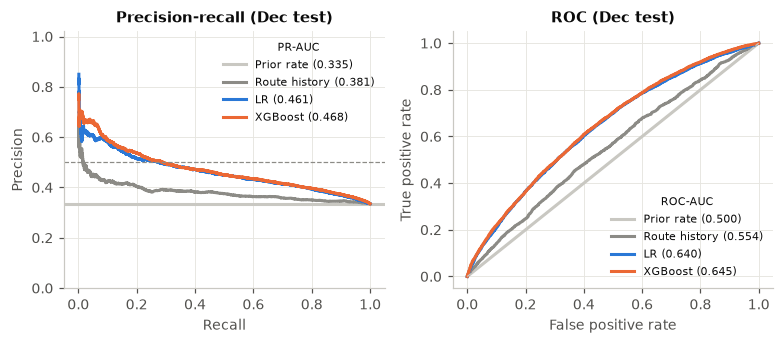

In [9]:
y = test["delayed"]
fig, axes = plt.subplots(1, 2, figsize=(7.2, 3.2))
for name, col in MODELS.items():
    color = MODEL_COLORS[name]
    ap = average_precision_score(y, test[col])
    if test[col].nunique() == 1:
        # a constant score has no real PR curve; its precision is the base rate everywhere
        axes[0].axhline(y.mean(), color=color, label=f"{name} ({ap:.3f})")
    else:
        p, r, _ = precision_recall_curve(y, test[col])
        # hide the first few points where fewer than 20 flights are flagged (pure noise)
        n_flagged = np.divide(r * y.sum(), p, out=np.zeros_like(r), where=p > 0)
        keep = n_flagged >= 20
        axes[0].plot(r[keep], p[keep], color=color, label=f"{name} ({ap:.3f})")
    fpr, tpr, _ = roc_curve(y, test[col])
    auc = roc_auc_score(y, test[col]) if test[col].nunique() > 1 else 0.5
    axes[1].plot(fpr, tpr, color=color, label=f"{name} ({auc:.3f})")
axes[0].axhline(TARGET_PRECISION, color=GREY, lw=0.8, ls="--")
axes[0].set(xlabel="Recall", ylabel="Precision", title="Precision-recall (Dec test)", ylim=(0, 1.02))
axes[1].plot([0, 1], [0, 1], color=LIGHT_GREY, lw=0.8, ls="--")
axes[1].set(xlabel="False positive rate", ylabel="True positive rate", title="ROC (Dec test)")
axes[0].legend(title="PR-AUC", loc="upper right", fontsize=7.5, title_fontsize=7.5)
axes[1].legend(title="ROC-AUC", loc="lower right", fontsize=7.5, title_fontsize=7.5)
fig.tight_layout()
fig.savefig(FIG_DIR / "pr_roc_test.png")
plt.show()

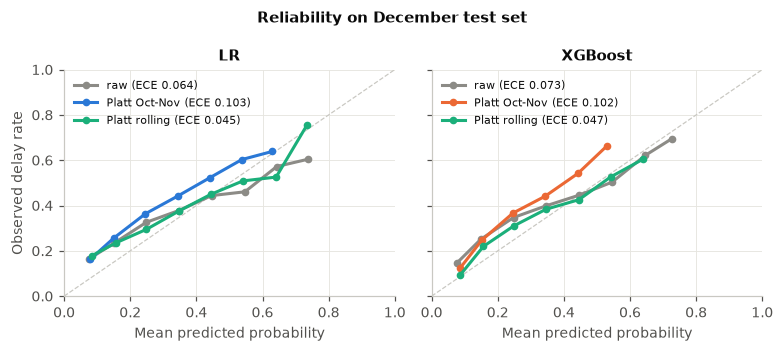

In [10]:
bins = 10
fig, axes = plt.subplots(1, 2, figsize=(7.2, 3.2), sharey=True)
yt = test["delayed"].to_numpy()
for ax, (m, name) in zip(axes, (("lr", "LR"), ("xgb", "XGBoost"))):
    ax.plot([0, 1], [0, 1], color=LIGHT_GREY, lw=0.8, ls="--")
    styles = (("raw", GREY, "raw"), ("cal", MODEL_COLORS[name], "Platt Oct-Nov"), ("roll", AQUA, "Platt rolling"))
    for kind, color, label in styles:
        p = test[f"p_{m}_{kind}"].to_numpy()
        edges = np.linspace(0, 1, bins + 1)
        idx = np.clip(np.digitize(p, edges[1:-1]), 0, bins - 1)
        xs = [p[idx == b].mean() for b in range(bins) if (idx == b).sum() >= 50]
        ys = [yt[idx == b].mean() for b in range(bins) if (idx == b).sum() >= 50]
        ax.plot(xs, ys, marker="o", ms=4, color=color,
                label=f"{label} (ECE {expected_calibration_error(yt, p):.3f})")
    ax.set(title=name, xlabel="Mean predicted probability", xlim=(0, 1), ylim=(0, 1))
    ax.legend(loc="upper left", fontsize=7.5)
axes[0].set_ylabel("Observed delay rate")
fig.suptitle("Reliability on December test set", fontsize=10, fontweight="bold")
fig.tight_layout()
fig.savefig(FIG_DIR / "reliability_test.png")
plt.show()

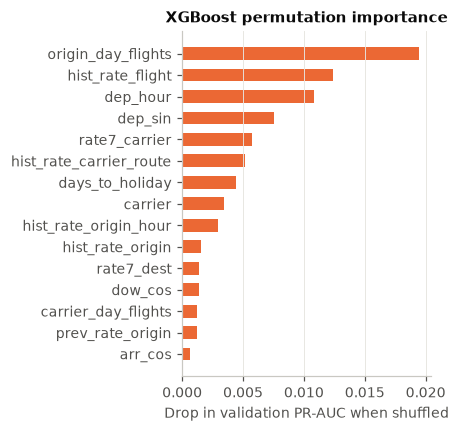

In [11]:
top = imp.head(15)[::-1]
fig, ax = plt.subplots(figsize=(4.2, 4.0))
ax.barh(top.index, top.values, color=ORANGE, height=0.6)
ax.set(xlabel="Drop in validation PR-AUC when shuffled", title="XGBoost permutation importance")
ax.grid(axis="y", visible=False)
fig.tight_layout()
fig.savefig(FIG_DIR / "permutation_importance.png")
plt.show()

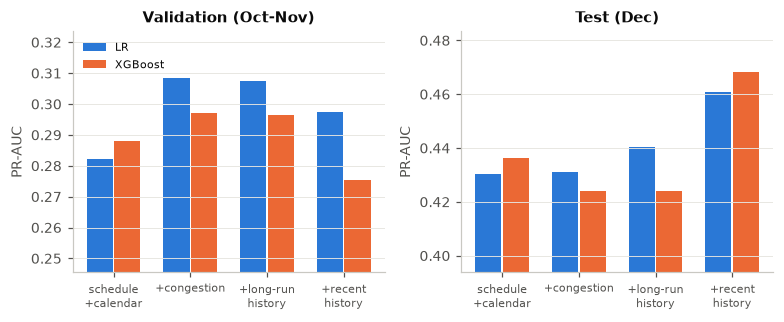

In [12]:
abl = pd.read_csv(RESULTS_DIR / "ablation.csv")
groups = list(dict.fromkeys(abl["features"]))
fig, axes = plt.subplots(1, 2, figsize=(7.2, 3.0))
x = np.arange(len(groups))
for ax, split, title in zip(axes, ("val", "test"), ("Validation (Oct-Nov)", "Test (Dec)")):
    for i, model in enumerate(("LR", "XGBoost")):
        sub = abl[(abl["split"] == split) & (abl["model"] == model)].set_index("features").loc[groups]
        ax.bar(x + (i - 0.5) * 0.36, sub["pr_auc"], width=0.34, label=model, color=MODEL_COLORS[model])
    lo = abl.loc[abl["split"] == split, "pr_auc"].min()
    hi = abl.loc[abl["split"] == split, "pr_auc"].max()
    ax.set_ylim(lo - 0.03, hi + 0.015)
    ax.set_xticks(x, [g.replace("+ ", "+").replace(" ", "\n", 1) for g in groups], fontsize=7.5)
    ax.set(title=title, ylabel="PR-AUC")
    ax.grid(axis="x", visible=False)
axes[0].legend(loc="upper left", fontsize=7.5)
fig.tight_layout()
fig.savefig(FIG_DIR / "ablation.png")
plt.show()

## LaTeX tables and number macros for the report and slides

In [13]:
lines = [r"\begin{tabular}{lcccc}", r"\toprule",
         r"Model & PR-AUC & ROC-AUC & Brier & ECE \\", r"\midrule"]
for _, r in metrics[metrics["model"].isin(MODELS)].iterrows():
    lines.append(f"{r['model']} & {r['test_pr_auc']:.3f} & {r['test_roc_auc']:.3f} & "
                 f"{r['test_brier']:.3f} & {r['test_ece']:.3f} \\\\")
lines += [r"\bottomrule", r"\end{tabular}"]
(TABLE_DIR / "metrics_test.tex").write_text("\n".join(lines) + "\n")

lines = [r"\begin{tabular}{lcccc}", r"\toprule",
         r"Model & Threshold & Flagged & Precision & Recall \\", r"\midrule"]
for _, r in metrics[metrics["threshold"].notna()].iterrows():
    lines.append(f"{r['model']} & {r['threshold']:.3f} & {100 * r['test_flagged_share']:.1f}\\% & "
                 f"{r['test_precision_at_thr']:.3f} & {r['test_recall_at_thr']:.3f} \\\\")
lines += [r"\bottomrule", r"\end{tabular}"]
(TABLE_DIR / "operating_point.tex").write_text("\n".join(lines) + "\n")

lines = [r"\begin{tabular}{llccc}", r"\toprule",
         r"Model & Probabilities & Brier & ECE & Mean $\hat p$ \\", r"\midrule"]
for _, r in calib.iterrows():
    lines.append(f"{r['model']} & {r['probabilities']} & {r['brier']:.4f} & {r['ece']:.4f} & {r['mean_pred']:.3f} \\\\")
lines += [r"\bottomrule", r"\end{tabular}"]
(TABLE_DIR / "calibration.tex").write_text("\n".join(lines) + "\n")

piv = abl.pivot_table(index="features", columns=["model", "split"], values="pr_auc", sort=False)
lines = [r"\begin{tabular}{lcccc}", r"\toprule",
         r" & \multicolumn{2}{c}{Validation} & \multicolumn{2}{c}{Test} \\",
         r"Feature set & LR & XGB & LR & XGB \\", r"\midrule"]
for g, r in piv.iterrows():
    lines.append(f"{g} & {r[('LR', 'val')]:.3f} & {r[('XGBoost', 'val')]:.3f} & "
                 f"{r[('LR', 'test')]:.3f} & {r[('XGBoost', 'test')]:.3f} \\\\")
lines += [r"\bottomrule", r"\end{tabular}"]
(TABLE_DIR / "ablation.tex").write_text("\n".join(lines) + "\n")

377

In [14]:
m = metrics.set_index("model")
c = calib.set_index(["model", "probabilities"])
macros = {
    "LRTestPRAUC": f"{m.loc['LR', 'test_pr_auc']:.3f}",
    "XGBTestPRAUC": f"{m.loc['XGBoost', 'test_pr_auc']:.3f}",
    "LRTestROCAUC": f"{m.loc['LR', 'test_roc_auc']:.3f}",
    "XGBTestROCAUC": f"{m.loc['XGBoost', 'test_roc_auc']:.3f}",
    "RouteTestPRAUC": f"{m.loc['Route history', 'test_pr_auc']:.3f}",
    "PriorTestPRAUC": f"{m.loc['Prior rate', 'test_pr_auc']:.3f}",
    "LRValPRAUC": f"{m.loc['LR', 'val_pr_auc']:.3f}",
    "XGBValPRAUC": f"{m.loc['XGBoost', 'val_pr_auc']:.3f}",
    "LRTestRecallThr": f"{m.loc['LR', 'test_recall_at_thr']:.3f}",
    "XGBTestRecallThr": f"{m.loc['XGBoost', 'test_recall_at_thr']:.3f}",
    "LRTestPrecThr": f"{m.loc['LR', 'test_precision_at_thr']:.3f}",
    "XGBTestPrecThr": f"{m.loc['XGBoost', 'test_precision_at_thr']:.3f}",
    "LRTestRecallPfifty": f"{m.loc['LR', 'test_recall_at_p50']:.3f}",
    "XGBTestRecallPfifty": f"{m.loc['XGBoost', 'test_recall_at_p50']:.3f}",
    "XGBRawECE": f"{c.loc[('XGBoost', 'raw'), 'ece']:.3f}",
    "XGBCalECE": f"{c.loc[('XGBoost', CAL_KINDS['cal']), 'ece']:.3f}",
    "XGBRollECE": f"{c.loc[('XGBoost', CAL_KINDS['roll']), 'ece']:.3f}",
    "LRRawECE": f"{c.loc[('LR', 'raw'), 'ece']:.3f}",
    "LRCalECE": f"{c.loc[('LR', CAL_KINDS['cal']), 'ece']:.3f}",
    "LRRollECE": f"{c.loc[('LR', CAL_KINDS['roll']), 'ece']:.3f}",
    "XGBMeanPredCal": f"{c.loc[('XGBoost', CAL_KINDS['cal']), 'mean_pred']:.3f}",
    "XGBRollPRAUC": f"{m.loc['XGBoost (rolling cal.)', 'test_pr_auc']:.3f}",
    "XGBRollRecallThr": f"{m.loc['XGBoost (rolling cal.)', 'test_recall_at_thr']:.3f}",
    "XGBRollPrecThr": f"{m.loc['XGBoost (rolling cal.)', 'test_precision_at_thr']:.3f}",
    "LRRollRecallThr": f"{m.loc['LR (rolling cal.)', 'test_recall_at_thr']:.3f}",
    "LRRollPrecThr": f"{m.loc['LR (rolling cal.)', 'test_precision_at_thr']:.3f}",
    "XGBRollWindow": f"{selected['rolling_calibration']['xgb']['window']}",
    "LRRollWindow": f"{selected['rolling_calibration']['lr']['window']}",
    "TestRate": f"{c.loc[('XGBoost', 'raw'), 'observed_rate']:.3f}",
    "ValRate": f"{m.loc['Prior rate', 'val_pr_auc']:.3f}",  # PR-AUC of a constant = base rate
    "TrainRate": f"{selected['train_positive_rate']:.3f}",
    "LRTrainPRAUC": f"{selected['train_fit']['lr']['pr_auc']:.3f}",
    "XGBTrainPRAUC": f"{selected['train_fit']['xgb']['pr_auc']:.3f}",
    "LRTrainROCAUC": f"{selected['train_fit']['lr']['roc_auc']:.3f}",
    "XGBTrainROCAUC": f"{selected['train_fit']['xgb']['roc_auc']:.3f}",
    "LRValROCAUC": f"{m.loc['LR', 'val_roc_auc']:.3f}",
    "XGBValROCAUC": f"{m.loc['XGBoost', 'val_roc_auc']:.3f}",
    "LRC": f"{selected['lr']['C']:g}",
    "XGBDepth": f"{selected['xgb']['max_depth']}",
    "XGBMinChild": f"{selected['xgb']['min_child_weight']}",
    "XGBLambda": f"{selected['xgb']['reg_lambda']}",
    "XGBTrees": f"{selected['xgb']['n_trees']}",
    "NTrain": f"{selected['n_rows']['train']:,}".replace(",", "{,}"),
    "NVal": f"{selected['n_rows']['val']:,}".replace(",", "{,}"),
    "NTest": f"{selected['n_rows']['test']:,}".replace(",", "{,}"),
}
with open(TABLE_DIR / "numbers.tex", "w") as f:
    for k, v in macros.items():
        f.write(f"\\newcommand{{\\{k}}}{{{v}}}\n")
print(f"wrote {len(macros)} macros")

wrote 45 macros
